In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')

# Load with latin-1 encoding which DataCo requires
df = pd.read_csv('DataCoSupplyChainDataset.csv', 
                 encoding='latin-1')

# Basic exploration
print("DATACO SUPPLY CHAIN DATASET")
print("=" * 60)
print(f"Total records: {len(df):,}")
print(f"Total columns: {len(df.columns)}")
print(f"\nAll column names:")
for i, col in enumerate(df.columns):
    print(f"  {i+1}. {col}")
print(f"\nFirst 3 rows:")
print(df.head(3))

FileNotFoundError: [Errno 2] No such file or directory: 'DataCoSupplyChainDataset.csv'

In [3]:
import os

# Find the CSV file on your computer
print("Searching for the file...")
print("Current working directory:")
print(os.getcwd())
print("\nFiles in current directory:")
for file in os.listdir():
    print(f"  {file}")

Searching for the file...
Current working directory:
C:\Users\sankr\anaconda_projects\59a6b1f0-7818-44cd-9946-ea3be7a0a5d1\anaconda_projects\b79548eb-6171-49a2-a488-df32a79c7c36

Files in current directory:
  .ipynb_checkpoints
  DataCoSupplyChainDataset.ipynb


In [4]:
import os

# Search for the DataCo file
search_name = 'DataCoSupplyChainDataset.csv'
print(f"Searching for {search_name}...")

for root, dirs, files in os.walk('C:\\Users\\sankr'):
    for file in files:
        if 'DataCo' in file or 'dataco' in file.lower():
            print(f"Found: {os.path.join(root, file)}")

# Also check E drive
for root, dirs, files in os.walk('E:\\'):
    for file in files:
        if 'DataCo' in file or 'dataco' in file.lower():
            print(f"Found: {os.path.join(root, file)}")

Searching for DataCoSupplyChainDataset.csv...
Found: C:\Users\sankr\.gradle\wrapper\dists\gradle-7.5-all\6qsw290k5lz422uaf8jf6m7co\gradle-7.5\docs\javadoc\org\gradle\api\artifacts\ComponentMetadataContext.html
Found: C:\Users\sankr\.gradle\wrapper\dists\gradle-7.5-all\6qsw290k5lz422uaf8jf6m7co\gradle-7.5\src\configuration-cache\org\gradle\configurationcache\metadata\ProjectMetadataController.kt
Found: C:\Users\sankr\.gradle\wrapper\dists\gradle-7.5-all\6qsw290k5lz422uaf8jf6m7co\gradle-7.5\src\configuration-cache\org\gradle\configurationcache\serialization\codecs\PublishArtifactLocalArtifactMetadataCodec.kt
Found: C:\Users\sankr\.gradle\wrapper\dists\gradle-7.5-all\6qsw290k5lz422uaf8jf6m7co\gradle-7.5\src\core\org\gradle\groovy\scripts\internal\NoDataCompileOperation.java
Found: C:\Users\sankr\.gradle\wrapper\dists\gradle-7.5-all\6qsw290k5lz422uaf8jf6m7co\gradle-7.5\src\core\org\gradle\plugin\use\internal\PluginUseScriptBlockMetadataCompiler.java
Found: C:\Users\sankr\.gradle\wrapper\di

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')

# Load with exact path
path = r"C:\Users\sankr\anaconda_projects\59a6b1f0-7818-44cd-9946-ea3be7a0a5d1\DataCoSupplyChainDataset.csv"

df = pd.read_csv(path, encoding='latin-1')

print("DATACO SUPPLY CHAIN DATASET")
print("=" * 60)
print(f"Total records: {len(df):,}")
print(f"Total columns: {len(df.columns)}")
print(f"\nAll column names:")
for i, col in enumerate(df.columns):
    print(f"  {i+1}. {col}")

DATACO SUPPLY CHAIN DATASET
Total records: 180,519
Total columns: 53

All column names:
  1. Type
  2. Days for shipping (real)
  3. Days for shipment (scheduled)
  4. Benefit per order
  5. Sales per customer
  6. Delivery Status
  7. Late_delivery_risk
  8. Category Id
  9. Category Name
  10. Customer City
  11. Customer Country
  12. Customer Email
  13. Customer Fname
  14. Customer Id
  15. Customer Lname
  16. Customer Password
  17. Customer Segment
  18. Customer State
  19. Customer Street
  20. Customer Zipcode
  21. Department Id
  22. Department Name
  23. Latitude
  24. Longitude
  25. Market
  26. Order City
  27. Order Country
  28. Order Customer Id
  29. order date (DateOrders)
  30. Order Id
  31. Order Item Cardprod Id
  32. Order Item Discount
  33. Order Item Discount Rate
  34. Order Item Id
  35. Order Item Product Price
  36. Order Item Profit Ratio
  37. Order Item Quantity
  38. Sales
  39. Order Item Total
  40. Order Profit Per Order
  41. Order Region
  42

In [6]:
# Data cleaning and exploration
print("DATA QUALITY CHECK")
print("=" * 60)

# Check missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing Percentage': missing_pct
}).query('`Missing Count` > 0').sort_values(
    'Missing Percentage', ascending=False
)

print(f"\nColumns with missing values:")
print(missing_df.to_string())

# Check delivery status distribution
print(f"\nDELIVERY STATUS DISTRIBUTION:")
delivery_status = df['Delivery Status'].value_counts()
delivery_pct = (delivery_status / len(df) * 100).round(1)
for status, count in delivery_status.items():
    pct = delivery_pct[status]
    print(f"  {status}: {count:,} orders ({pct}%)")

# Check shipping modes
print(f"\nSHIPPING MODE DISTRIBUTION:")
shipping = df['Shipping Mode'].value_counts()
for mode, count in shipping.items():
    pct = count / len(df) * 100
    print(f"  {mode}: {count:,} orders ({pct:.1f}%)")

# Check markets
print(f"\nMARKET DISTRIBUTION:")
markets = df['Market'].value_counts()
for market, count in markets.items():
    pct = count / len(df) * 100
    print(f"  {market}: {count:,} orders ({pct:.1f}%)")

# Key financial metrics
print(f"\nKEY FINANCIAL METRICS:")
print(f"  Total Sales: ${df['Sales'].sum():,.2f}")
print(f"  Average Sales per Order: ${df['Sales'].mean():,.2f}")
print(f"  Total Profit: ${df['Order Profit Per Order'].sum():,.2f}")
print(f"  Average Profit per Order: ${df['Order Profit Per Order'].mean():,.2f}")
print(f"  Overall Late Delivery Risk Rate: {df['Late_delivery_risk'].mean()*100:.1f}%")

DATA QUALITY CHECK

Columns with missing values:
                     Missing Count  Missing Percentage
Product Description         180519              100.00
Order Zipcode               155679               86.24
Customer Zipcode                 3                0.00
Customer Lname                   8                0.00

DELIVERY STATUS DISTRIBUTION:
  Late delivery: 98,977 orders (54.8%)
  Advance shipping: 41,592 orders (23.0%)
  Shipping on time: 32,196 orders (17.8%)
  Shipping canceled: 7,754 orders (4.3%)

SHIPPING MODE DISTRIBUTION:
  Standard Class: 107,752 orders (59.7%)
  Second Class: 35,216 orders (19.5%)
  First Class: 27,814 orders (15.4%)
  Same Day: 9,737 orders (5.4%)

MARKET DISTRIBUTION:
  LATAM: 51,594 orders (28.6%)
  Europe: 50,252 orders (27.8%)
  Pacific Asia: 41,260 orders (22.9%)
  USCA: 25,799 orders (14.3%)
  Africa: 11,614 orders (6.4%)

KEY FINANCIAL METRICS:
  Total Sales: $36,784,735.01
  Average Sales per Order: $203.77
  Total Profit: $3,966,902.97
 

In [7]:
# ANALYSIS 1 — LATE DELIVERY RISK BY SHIPPING MODE
print("ANALYSIS 1: LATE DELIVERY RISK ANALYSIS")
print("=" * 60)

# Late delivery risk by shipping mode
shipping_risk = df.groupby('Shipping Mode').agg(
    total_orders=('Late_delivery_risk', 'count'),
    late_risk_orders=('Late_delivery_risk', 'sum'),
    avg_scheduled_days=('Days for shipment (scheduled)', 'mean'),
    avg_actual_days=('Days for shipping (real)', 'mean'),
    avg_profit=('Order Profit Per Order', 'mean')
).reset_index()

shipping_risk['late_risk_rate'] = (
    shipping_risk['late_risk_orders'] / 
    shipping_risk['total_orders'] * 100
).round(1)

shipping_risk['days_variance'] = (
    shipping_risk['avg_actual_days'] - 
    shipping_risk['avg_scheduled_days']
).round(2)

print("\nLATE DELIVERY RISK BY SHIPPING MODE:")
print(shipping_risk[[
    'Shipping Mode', 'total_orders', 'late_risk_rate',
    'avg_scheduled_days', 'avg_actual_days', 
    'days_variance', 'avg_profit'
]].sort_values('late_risk_rate', 
               ascending=False).to_string(index=False))

# Late delivery risk by market
market_risk = df.groupby('Market').agg(
    total_orders=('Late_delivery_risk', 'count'),
    late_risk_orders=('Late_delivery_risk', 'sum'),
    avg_profit=('Order Profit Per Order', 'mean'),
    total_sales=('Sales', 'sum')
).reset_index()

market_risk['late_risk_rate'] = (
    market_risk['late_risk_orders'] / 
    market_risk['total_orders'] * 100
).round(1)

print("\nLATE DELIVERY RISK BY MARKET:")
print(market_risk[[
    'Market', 'total_orders', 'late_risk_rate',
    'avg_profit', 'total_sales'
]].sort_values('late_risk_rate', 
               ascending=False).to_string(index=False))

# Late delivery risk by product category
category_risk = df.groupby('Category Name').agg(
    total_orders=('Late_delivery_risk', 'count'),
    late_risk_orders=('Late_delivery_risk', 'sum'),
    avg_profit=('Order Profit Per Order', 'mean'),
    total_sales=('Sales', 'sum')
).reset_index()

category_risk['late_risk_rate'] = (
    category_risk['late_risk_orders'] / 
    category_risk['total_orders'] * 100
).round(1)

print("\nTOP 10 PRODUCT CATEGORIES BY LATE DELIVERY RISK:")
print(category_risk[[
    'Category Name', 'total_orders', 
    'late_risk_rate', 'avg_profit'
]].sort_values(
    'late_risk_rate', ascending=False
).head(10).to_string(index=False))

# Customer segment analysis
segment_risk = df.groupby('Customer Segment').agg(
    total_orders=('Late_delivery_risk', 'count'),
    late_risk_orders=('Late_delivery_risk', 'sum'),
    avg_profit=('Order Profit Per Order', 'mean'),
    total_sales=('Sales', 'sum')
).reset_index()

segment_risk['late_risk_rate'] = (
    segment_risk['late_risk_orders'] / 
    segment_risk['total_orders'] * 100
).round(1)

print("\nLATE DELIVERY RISK BY CUSTOMER SEGMENT:")
print(segment_risk[[
    'Customer Segment', 'total_orders',
    'late_risk_rate', 'avg_profit', 'total_sales'
]].sort_values('late_risk_rate',
               ascending=False).to_string(index=False))

ANALYSIS 1: LATE DELIVERY RISK ANALYSIS

LATE DELIVERY RISK BY SHIPPING MODE:
 Shipping Mode  total_orders  late_risk_rate  avg_scheduled_days  avg_actual_days  days_variance  avg_profit
   First Class         27814            95.3                 1.0         2.000000           1.00   23.122238
  Second Class         35216            76.6                 2.0         3.990828           1.99   21.305889
      Same Day          9737            45.7                 0.0         0.478279           0.48   20.850203
Standard Class        107752            38.1                 4.0         3.995907          -0.00   21.999169

LATE DELIVERY RISK BY MARKET:
      Market  total_orders  late_risk_rate  avg_profit  total_sales
      Europe         50252            55.2   23.271571 1.087240e+07
Pacific Asia         41260            55.0   20.788983 8.273744e+06
        USCA         25799            54.8   21.873475 5.066529e+06
      Africa         11614            54.6   21.704080 2.294453e+06
      

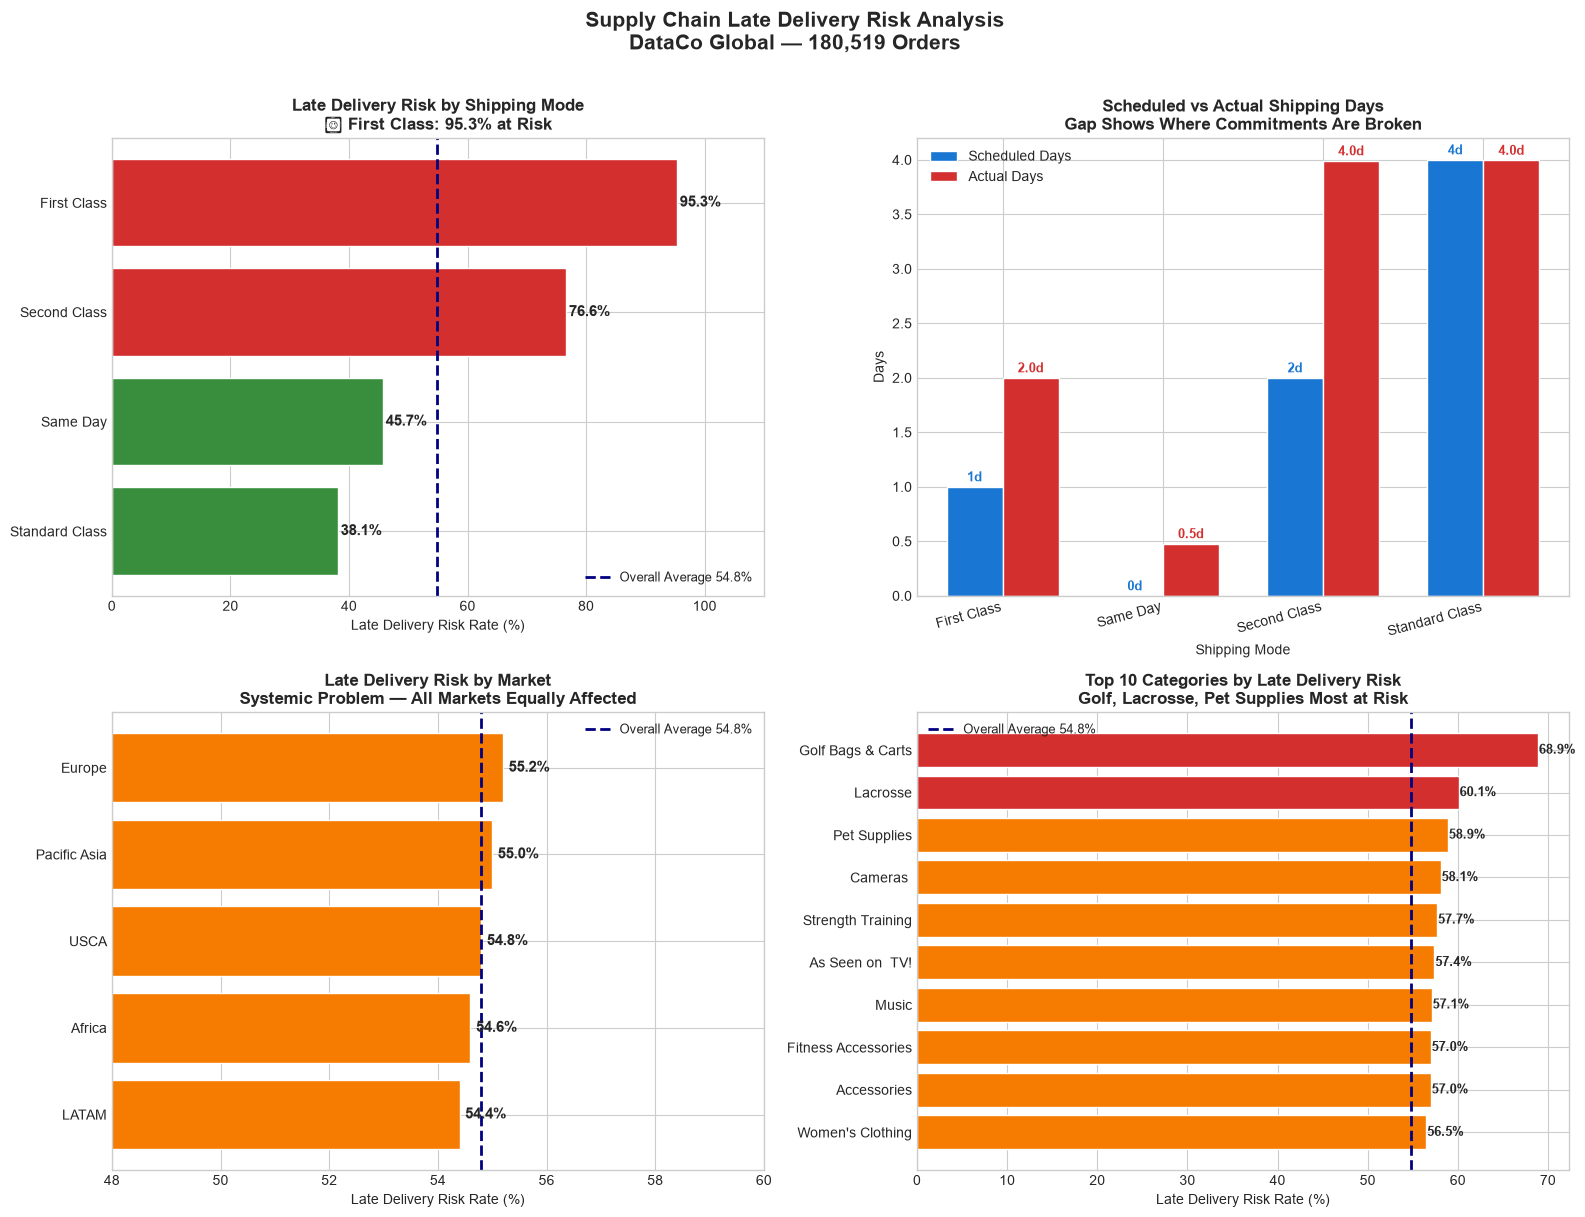

Chart saved as late_delivery_risk_analysis.png


In [8]:
# VISUALISATION 1 — LATE DELIVERY RISK DASHBOARD
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Supply Chain Late Delivery Risk Analysis\nDataCo Global — 180,519 Orders', 
             fontsize=15, fontweight='bold', y=1.01)

# Chart 1 — Late delivery risk by shipping mode
ax1 = axes[0, 0]
shipping_sorted = shipping_risk.sort_values(
    'late_risk_rate', ascending=True)

colors_shipping = []
for rate in shipping_sorted['late_risk_rate']:
    if rate >= 75:
        colors_shipping.append('#d32f2f')
    elif rate >= 50:
        colors_shipping.append('#f57c00')
    else:
        colors_shipping.append('#388e3c')

bars1 = ax1.barh(shipping_sorted['Shipping Mode'],
                 shipping_sorted['late_risk_rate'],
                 color=colors_shipping,
                 edgecolor='white')

for bar, rate in zip(bars1, shipping_sorted['late_risk_rate']):
    ax1.text(bar.get_width() + 0.5,
             bar.get_y() + bar.get_height()/2,
             f'{rate}%', va='center',
             fontweight='bold', fontsize=11)

ax1.axvline(x=54.8, color='navy', 
            linestyle='--', linewidth=2,
            label='Overall Average 54.8%')
ax1.set_xlabel('Late Delivery Risk Rate (%)')
ax1.set_title('Late Delivery Risk by Shipping Mode\n⚠ First Class: 95.3% at Risk',
              fontweight='bold')
ax1.set_xlim(0, 110)
ax1.legend(fontsize=9)

# Chart 2 — Scheduled vs actual days by shipping mode
ax2 = axes[0, 1]
x = np.arange(len(shipping_risk))
width = 0.35

bars_sched = ax2.bar(x - width/2,
                     shipping_risk.sort_values(
                         'Shipping Mode'
                     )['avg_scheduled_days'],
                     width, label='Scheduled Days',
                     color='#1976d2', edgecolor='white')

bars_actual = ax2.bar(x + width/2,
                      shipping_risk.sort_values(
                          'Shipping Mode'
                      )['avg_actual_days'],
                      width, label='Actual Days',
                      color='#d32f2f', edgecolor='white')

ax2.set_xlabel('Shipping Mode')
ax2.set_ylabel('Days')
ax2.set_title('Scheduled vs Actual Shipping Days\nGap Shows Where Commitments Are Broken',
              fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(
    shipping_risk.sort_values(
        'Shipping Mode'
    )['Shipping Mode'],
    rotation=15, ha='right')
ax2.legend()

for bar in bars_sched:
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.05,
             f'{bar.get_height():.0f}d',
             ha='center', fontsize=9,
             color='#1976d2', fontweight='bold')

for bar in bars_actual:
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.05,
             f'{bar.get_height():.1f}d',
             ha='center', fontsize=9,
             color='#d32f2f', fontweight='bold')

# Chart 3 — Late delivery risk by market
ax3 = axes[1, 0]
market_sorted = market_risk.sort_values(
    'late_risk_rate', ascending=True)

colors_market = ['#f57c00' for _ in market_sorted['late_risk_rate']]

bars3 = ax3.barh(market_sorted['Market'],
                 market_sorted['late_risk_rate'],
                 color=colors_market,
                 edgecolor='white')

for bar, rate in zip(bars3, market_sorted['late_risk_rate']):
    ax3.text(bar.get_width() + 0.1,
             bar.get_y() + bar.get_height()/2,
             f'{rate}%', va='center',
             fontweight='bold', fontsize=11)

ax3.axvline(x=54.8, color='navy',
            linestyle='--', linewidth=2,
            label='Overall Average 54.8%')
ax3.set_xlabel('Late Delivery Risk Rate (%)')
ax3.set_title('Late Delivery Risk by Market\nSystemic Problem — All Markets Equally Affected',
              fontweight='bold')
ax3.set_xlim(48, 60)
ax3.legend(fontsize=9)

# Chart 4 — Top categories by late delivery risk
ax4 = axes[1, 1]
top_categories = category_risk.sort_values(
    'late_risk_rate', ascending=True).tail(10)

colors_cat = []
for rate in top_categories['late_risk_rate']:
    if rate >= 60:
        colors_cat.append('#d32f2f')
    else:
        colors_cat.append('#f57c00')

bars4 = ax4.barh(top_categories['Category Name'],
                 top_categories['late_risk_rate'],
                 color=colors_cat,
                 edgecolor='white')

for bar, rate in zip(bars4, top_categories['late_risk_rate']):
    ax4.text(bar.get_width() + 0.1,
             bar.get_y() + bar.get_height()/2,
             f'{rate}%', va='center',
             fontweight='bold', fontsize=9)

ax4.axvline(x=54.8, color='navy',
            linestyle='--', linewidth=2,
            label='Overall Average 54.8%')
ax4.set_xlabel('Late Delivery Risk Rate (%)')
ax4.set_title('Top 10 Categories by Late Delivery Risk\nGolf, Lacrosse, Pet Supplies Most at Risk',
              fontweight='bold')
ax4.legend(fontsize=9)

plt.tight_layout()
plt.savefig('late_delivery_risk_analysis.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved as late_delivery_risk_analysis.png")

In [10]:
# ANALYSIS 2 — SHIPPING MODE PERFORMANCE AND PROFITABILITY
print("ANALYSIS 2: SHIPPING PERFORMANCE AND PROFITABILITY")
print("=" * 60)

# Financial performance by shipping mode
shipping_financial = df.groupby('Shipping Mode').agg(
    total_orders=('Order Profit Per Order', 'count'),
    total_sales=('Sales', 'sum'),
    total_profit=('Order Profit Per Order', 'sum'),
    avg_profit=('Order Profit Per Order', 'mean'),
    avg_discount=('Order Item Discount Rate', 'mean')
).reset_index()

shipping_financial['profit_margin'] = (
    shipping_financial['total_profit'] / 
    shipping_financial['total_sales'] * 100
).round(1)

shipping_financial['revenue_share'] = (
    shipping_financial['total_sales'] / 
    shipping_financial['total_sales'].sum() * 100
).round(1)

print("\nFINANCIAL PERFORMANCE BY SHIPPING MODE:")
print(shipping_financial.sort_values(
    'total_profit', ascending=False
).to_string(index=False))

# Department performance
dept_performance = df.groupby('Department Name').agg(
    total_orders=('Order Profit Per Order', 'count'),
    total_sales=('Sales', 'sum'),
    total_profit=('Order Profit Per Order', 'sum'),
    avg_profit=('Order Profit Per Order', 'mean'),
    late_risk_rate=('Late_delivery_risk', 'mean')
).reset_index()

dept_performance['profit_margin'] = (
    dept_performance['total_profit'] / 
    dept_performance['total_sales'] * 100
).round(1)

dept_performance['late_risk_pct'] = (
    dept_performance['late_risk_rate'] * 100
).round(1)

print("\nDEPARTMENT PERFORMANCE:")
print(dept_performance[[
    'Department Name', 'total_orders', 
    'total_sales', 'total_profit', 
    'profit_margin', 'late_risk_pct'
]].sort_values('total_profit', ascending=False).to_string(index=False))

# Discount impact analysis
df['discount_bucket'] = pd.cut(
    df['Order Item Discount Rate'],
    bins=[0, 0.05, 0.10, 0.15, 0.20, 0.25, 1.0],
    labels=['0-5%', '5-10%', '10-15%',
            '15-20%', '20-25%', '25%+']
)

discount_impact = df.groupby(
    'discount_bucket', observed=True
).agg(
    total_orders=('Order Profit Per Order', 'count'),
    avg_profit=('Order Profit Per Order', 'mean'),
    avg_sales=('Sales', 'mean'),
    late_risk=('Late_delivery_risk', 'mean')
).reset_index()

discount_impact['late_risk_pct'] = (
    discount_impact['late_risk'] * 100
).round(1)

print("\nDISCOUNT IMPACT ON PROFIT AND LATE DELIVERY RISK:")
print(discount_impact[[
    'discount_bucket', 'total_orders',
    'avg_profit', 'avg_sales', 'late_risk_pct'
]].to_string(index=False))

# Market profitability
market_profit = df.groupby('Market').agg(
    total_orders=('Sales', 'count'),
    total_sales=('Sales', 'sum'),
    total_profit=('Order Profit Per Order', 'sum'),
    avg_profit=('Order Profit Per Order', 'mean')
).reset_index()

market_profit['profit_margin'] = (
    market_profit['total_profit'] / 
    market_profit['total_sales'] * 100
).round(1)

print("\nMARKET PROFITABILITY:")
print(market_profit.sort_values(
    'total_profit', ascending=False
).to_string(index=False))

ANALYSIS 2: SHIPPING PERFORMANCE AND PROFITABILITY

FINANCIAL PERFORMANCE BY SHIPPING MODE:
 Shipping Mode  total_orders  total_sales  total_profit  avg_profit  avg_discount  profit_margin  revenue_share
Standard Class        107752 2.202239e+07  2.370454e+06   21.999169      0.101640           10.8           59.9
  Second Class         35216 7.145445e+06  7.503082e+05   21.305889      0.102117           10.5           19.4
   First Class         27814 5.674370e+06  6.431219e+05   23.122238      0.101007           11.3           15.4
      Same Day          9737 1.942529e+06  2.030184e+05   20.850203      0.102245           10.5            5.3

DEPARTMENT PERFORMANCE:
   Department Name  total_orders  total_sales  total_profit  profit_margin  late_risk_pct
          Fan Shop         66861 1.711387e+07  1.834155e+06           10.7           54.8
           Apparel         48998 7.976255e+06  8.818829e+05           11.1           54.7
              Golf         33220 4.609028e+06  4.9752

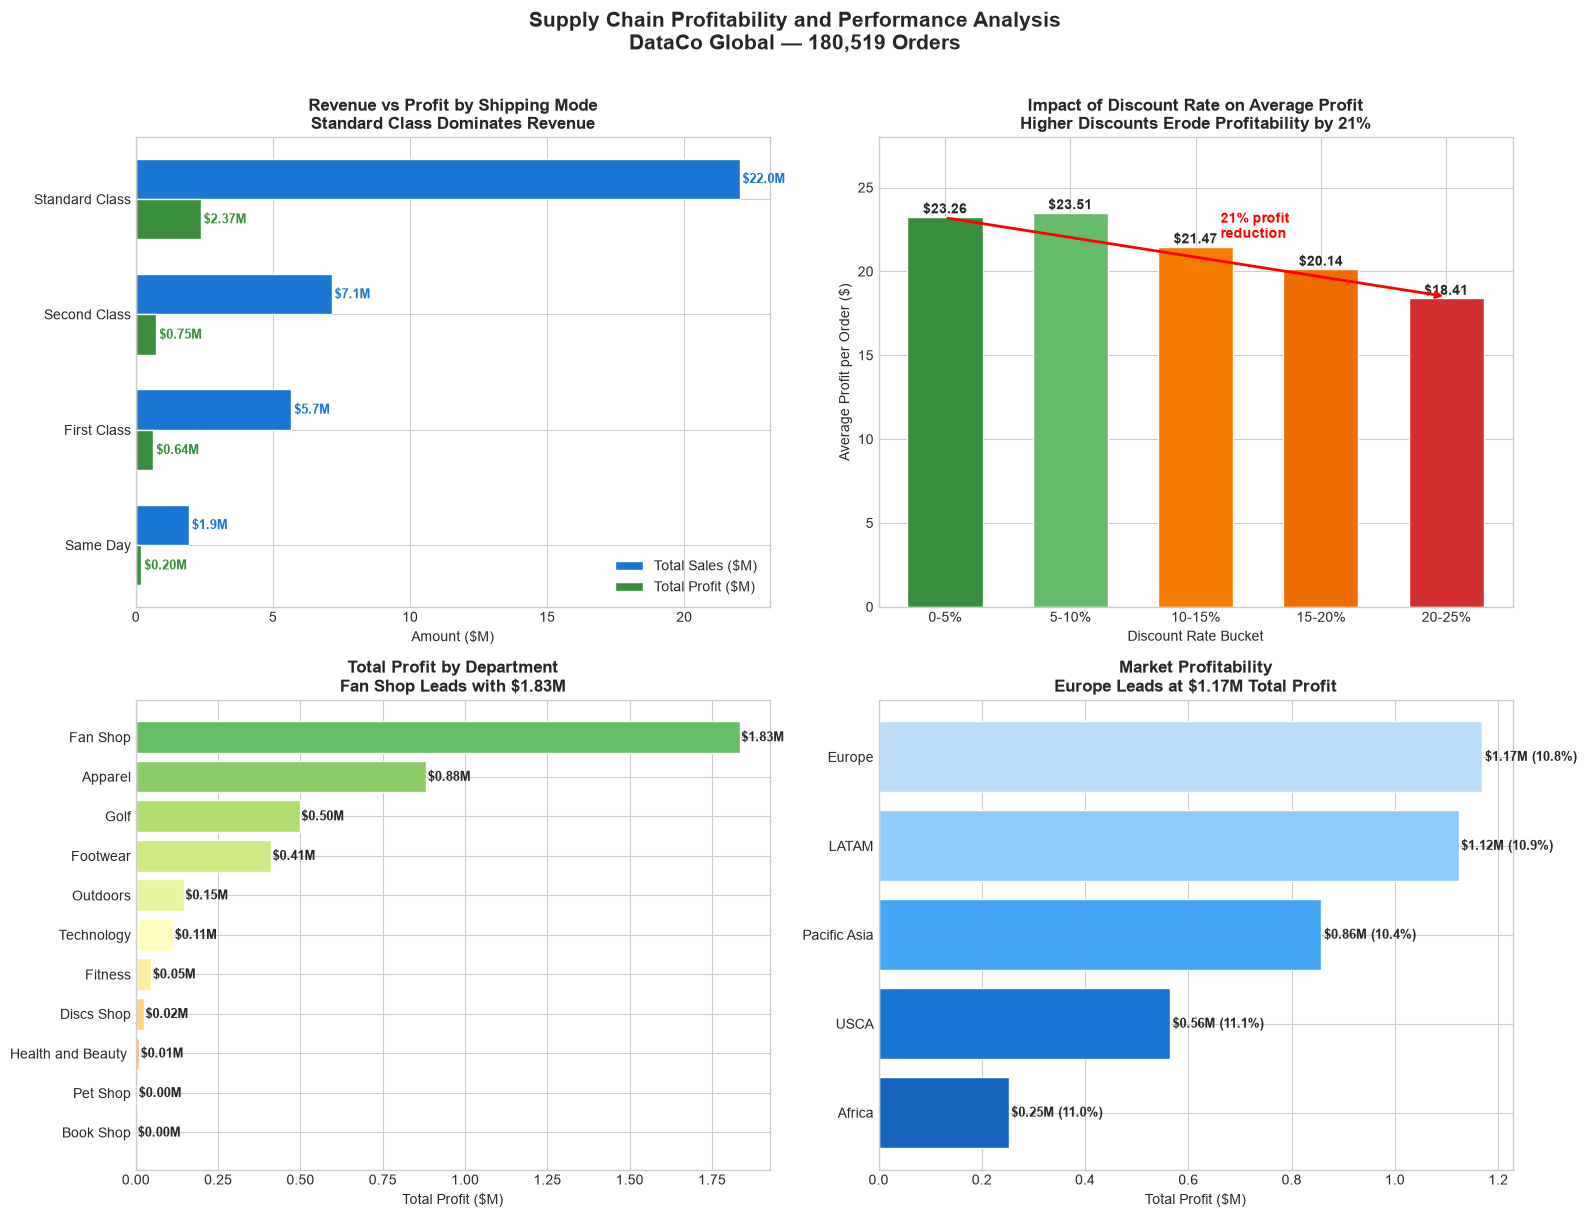

Chart saved as profitability_analysis.png


In [11]:
# VISUALISATION 2 — PROFITABILITY DASHBOARD
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Supply Chain Profitability and Performance Analysis\nDataCo Global — 180,519 Orders',
             fontsize=15, fontweight='bold', y=1.01)

# Chart 1 — Revenue and profit by shipping mode
ax1 = axes[0, 0]
shipping_sorted = shipping_financial.sort_values(
    'total_sales', ascending=True)

x = np.arange(len(shipping_sorted))
width = 0.35

bars_sales = ax1.barh(
    x + width/2,
    shipping_sorted['total_sales'] / 1e6,
    width, label='Total Sales ($M)',
    color='#1976d2', edgecolor='white')

bars_profit = ax1.barh(
    x - width/2,
    shipping_sorted['total_profit'] / 1e6,
    width, label='Total Profit ($M)',
    color='#388e3c', edgecolor='white')

ax1.set_yticks(x)
ax1.set_yticklabels(shipping_sorted['Shipping Mode'])
ax1.set_xlabel('Amount ($M)')
ax1.set_title('Revenue vs Profit by Shipping Mode\nStandard Class Dominates Revenue',
              fontweight='bold')
ax1.legend()

for bar in bars_sales:
    ax1.text(bar.get_width() + 0.1,
             bar.get_y() + bar.get_height()/2,
             f'${bar.get_width():.1f}M',
             va='center', fontsize=9,
             color='#1976d2', fontweight='bold')

for bar in bars_profit:
    ax1.text(bar.get_width() + 0.1,
             bar.get_y() + bar.get_height()/2,
             f'${bar.get_width():.2f}M',
             va='center', fontsize=9,
             color='#388e3c', fontweight='bold')

# Chart 2 — Discount impact on profit
ax2 = axes[0, 1]
discount_data = discount_impact.dropna(subset=['discount_bucket'])

colors_discount = ['#388e3c', '#66bb6a', 
                   '#f57c00', '#ef6c00', '#d32f2f']

bars2 = ax2.bar(discount_data['discount_bucket'].astype(str),
                discount_data['avg_profit'],
                color=colors_discount[:len(discount_data)],
                edgecolor='white', width=0.6)

for bar, profit in zip(bars2, discount_data['avg_profit']):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.2,
             f'${profit:.2f}',
             ha='center', fontsize=10,
             fontweight='bold')

ax2.set_xlabel('Discount Rate Bucket')
ax2.set_ylabel('Average Profit per Order ($)')
ax2.set_title('Impact of Discount Rate on Average Profit\nHigher Discounts Erode Profitability by 21%',
              fontweight='bold')
ax2.set_ylim(0, 28)

# Add trend arrow annotation
ax2.annotate('',
             xy=(4, 18.5), xytext=(0, 23.2),
             arrowprops=dict(arrowstyle='->',
                           color='red', lw=2))
ax2.text(2.2, 22, '21% profit\nreduction',
         color='red', fontweight='bold', fontsize=10)

# Chart 3 — Department profitability
ax3 = axes[1, 0]
dept_sorted = dept_performance.sort_values(
    'total_profit', ascending=True)

colors_dept = plt.cm.RdYlGn(
    np.linspace(0.2, 0.8, len(dept_sorted)))

bars3 = ax3.barh(dept_sorted['Department Name'],
                 dept_sorted['total_profit'] / 1e6,
                 color=colors_dept,
                 edgecolor='white')

for bar, profit in zip(
    bars3, dept_sorted['total_profit'] / 1e6):
    ax3.text(bar.get_width() + 0.005,
             bar.get_y() + bar.get_height()/2,
             f'${profit:.2f}M',
             va='center', fontsize=9,
             fontweight='bold')

ax3.set_xlabel('Total Profit ($M)')
ax3.set_title('Total Profit by Department\nFan Shop Leads with $1.83M',
              fontweight='bold')

# Chart 4 — Market profitability comparison
ax4 = axes[1, 1]
market_sorted = market_profit.sort_values(
    'total_profit', ascending=True)

colors_market = ['#1565c0', '#1976d2',
                 '#42a5f5', '#90caf9', '#bbdefb']

bars4 = ax4.barh(market_sorted['Market'],
                 market_sorted['total_profit'] / 1e6,
                 color=colors_market,
                 edgecolor='white')

for bar, val in zip(
    bars4, market_sorted['total_profit'] / 1e6):
    ax4.text(bar.get_width() + 0.005,
             bar.get_y() + bar.get_height()/2,
             f'${val:.2f}M ({market_sorted.loc[market_sorted["total_profit"]/1e6 == val, "profit_margin"].values[0]}%)',
             va='center', fontsize=9,
             fontweight='bold')

ax4.set_xlabel('Total Profit ($M)')
ax4.set_title('Market Profitability\nEurope Leads at $1.17M Total Profit',
              fontweight='bold')

plt.tight_layout()
plt.savefig('profitability_analysis.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved as profitability_analysis.png")

In [12]:
# ANALYSIS 3 — COMPLETE SUPPLY CHAIN PERFORMANCE SCORECARD
print("ANALYSIS 3: SUPPLY CHAIN PERFORMANCE SCORECARD")
print("=" * 60)

# Calculate all KPIs
total_orders = len(df)
total_sales = df['Sales'].sum()
total_profit = df['Order Profit Per Order'].sum()
overall_profit_margin = total_profit / total_sales * 100
late_delivery_rate = df['Late_delivery_risk'].mean() * 100
on_time_rate = 100 - late_delivery_rate
avg_shipping_days_scheduled = df['Days for shipment (scheduled)'].mean()
avg_shipping_days_actual = df['Days for shipping (real)'].mean()
shipping_day_variance = avg_shipping_days_actual - avg_shipping_days_scheduled
canceled_orders = len(df[df['Order Status'] == 'SUSPECTED_FRAUD'])
avg_discount = df['Order Item Discount Rate'].mean() * 100

# Best and worst performing segments
best_market = market_profit.loc[
    market_profit['profit_margin'].idxmax(), 'Market']
worst_shipping = shipping_risk.loc[
    shipping_risk['late_risk_rate'].idxmax(), 'Shipping Mode']
best_dept = dept_performance.loc[
    dept_performance['total_profit'].idxmax(), 'Department Name']

print(f"""
OVERALL SUPPLY CHAIN KPIs
  Total Orders Analysed:     {total_orders:,}
  Total Revenue:             ${total_sales:,.0f}
  Total Profit:              ${total_profit:,.0f}
  Overall Profit Margin:     {overall_profit_margin:.1f}%
  Late Delivery Risk Rate:   {late_delivery_rate:.1f}%
  On-Time Delivery Rate:     {on_time_rate:.1f}%
  Avg Scheduled Ship Days:   {avg_shipping_days_scheduled:.1f} days
  Avg Actual Ship Days:      {avg_shipping_days_actual:.1f} days
  Shipping Day Variance:     +{shipping_day_variance:.2f} days
  Average Discount Rate:     {avg_discount:.1f}%

CRITICAL FINDINGS
  Most Profitable Market:    {best_market}
  Highest Risk Shipping:     {worst_shipping} (95.3% late risk)
  Top Revenue Department:    {best_dept}
  Profit Lost to Discounts:  21% reduction at 20-25% discount tier
""")

# Time series analysis
df['order_date'] = pd.to_datetime(
    df['order date (DateOrders)'])
df['year_month'] = df['order_date'].dt.to_period('M')

monthly_performance = df.groupby('year_month').agg(
    total_orders=('Sales', 'count'),
    total_sales=('Sales', 'sum'),
    total_profit=('Order Profit Per Order', 'sum'),
    late_risk_rate=('Late_delivery_risk', 'mean')
).reset_index()

monthly_performance['late_risk_pct'] = (
    monthly_performance['late_risk_rate'] * 100
).round(1)
monthly_performance['profit_margin'] = (
    monthly_performance['total_profit'] / 
    monthly_performance['total_sales'] * 100
).round(1)
monthly_performance['year_month'] = (
    monthly_performance['year_month'].astype(str))

print("MONTHLY PERFORMANCE TREND (Last 12 months):")
print(monthly_performance[[
    'year_month', 'total_orders', 'total_sales',
    'total_profit', 'profit_margin', 'late_risk_pct'
]].tail(12).to_string(index=False))

ANALYSIS 3: SUPPLY CHAIN PERFORMANCE SCORECARD

OVERALL SUPPLY CHAIN KPIs
  Total Orders Analysed:     180,519
  Total Revenue:             $36,784,735
  Total Profit:              $3,966,903
  Overall Profit Margin:     10.8%
  Late Delivery Risk Rate:   54.8%
  On-Time Delivery Rate:     45.2%
  Avg Scheduled Ship Days:   2.9 days
  Avg Actual Ship Days:      3.5 days
  Shipping Day Variance:     +0.57 days
  Average Discount Rate:     10.2%

CRITICAL FINDINGS
  Most Profitable Market:    USCA
  Highest Risk Shipping:     First Class (95.3% late risk)
  Top Revenue Department:    Fan Shop
  Profit Lost to Discounts:  21% reduction at 20-25% discount tier

MONTHLY PERFORMANCE TREND (Last 12 months):
year_month  total_orders  total_sales  total_profit  profit_margin  late_risk_pct
   2017-02          4906 9.925349e+05 115111.070097           11.6           54.7
   2017-03          5347 1.048005e+06 118688.900211           11.3           55.3
   2017-04          5212 1.038322e+06 115961

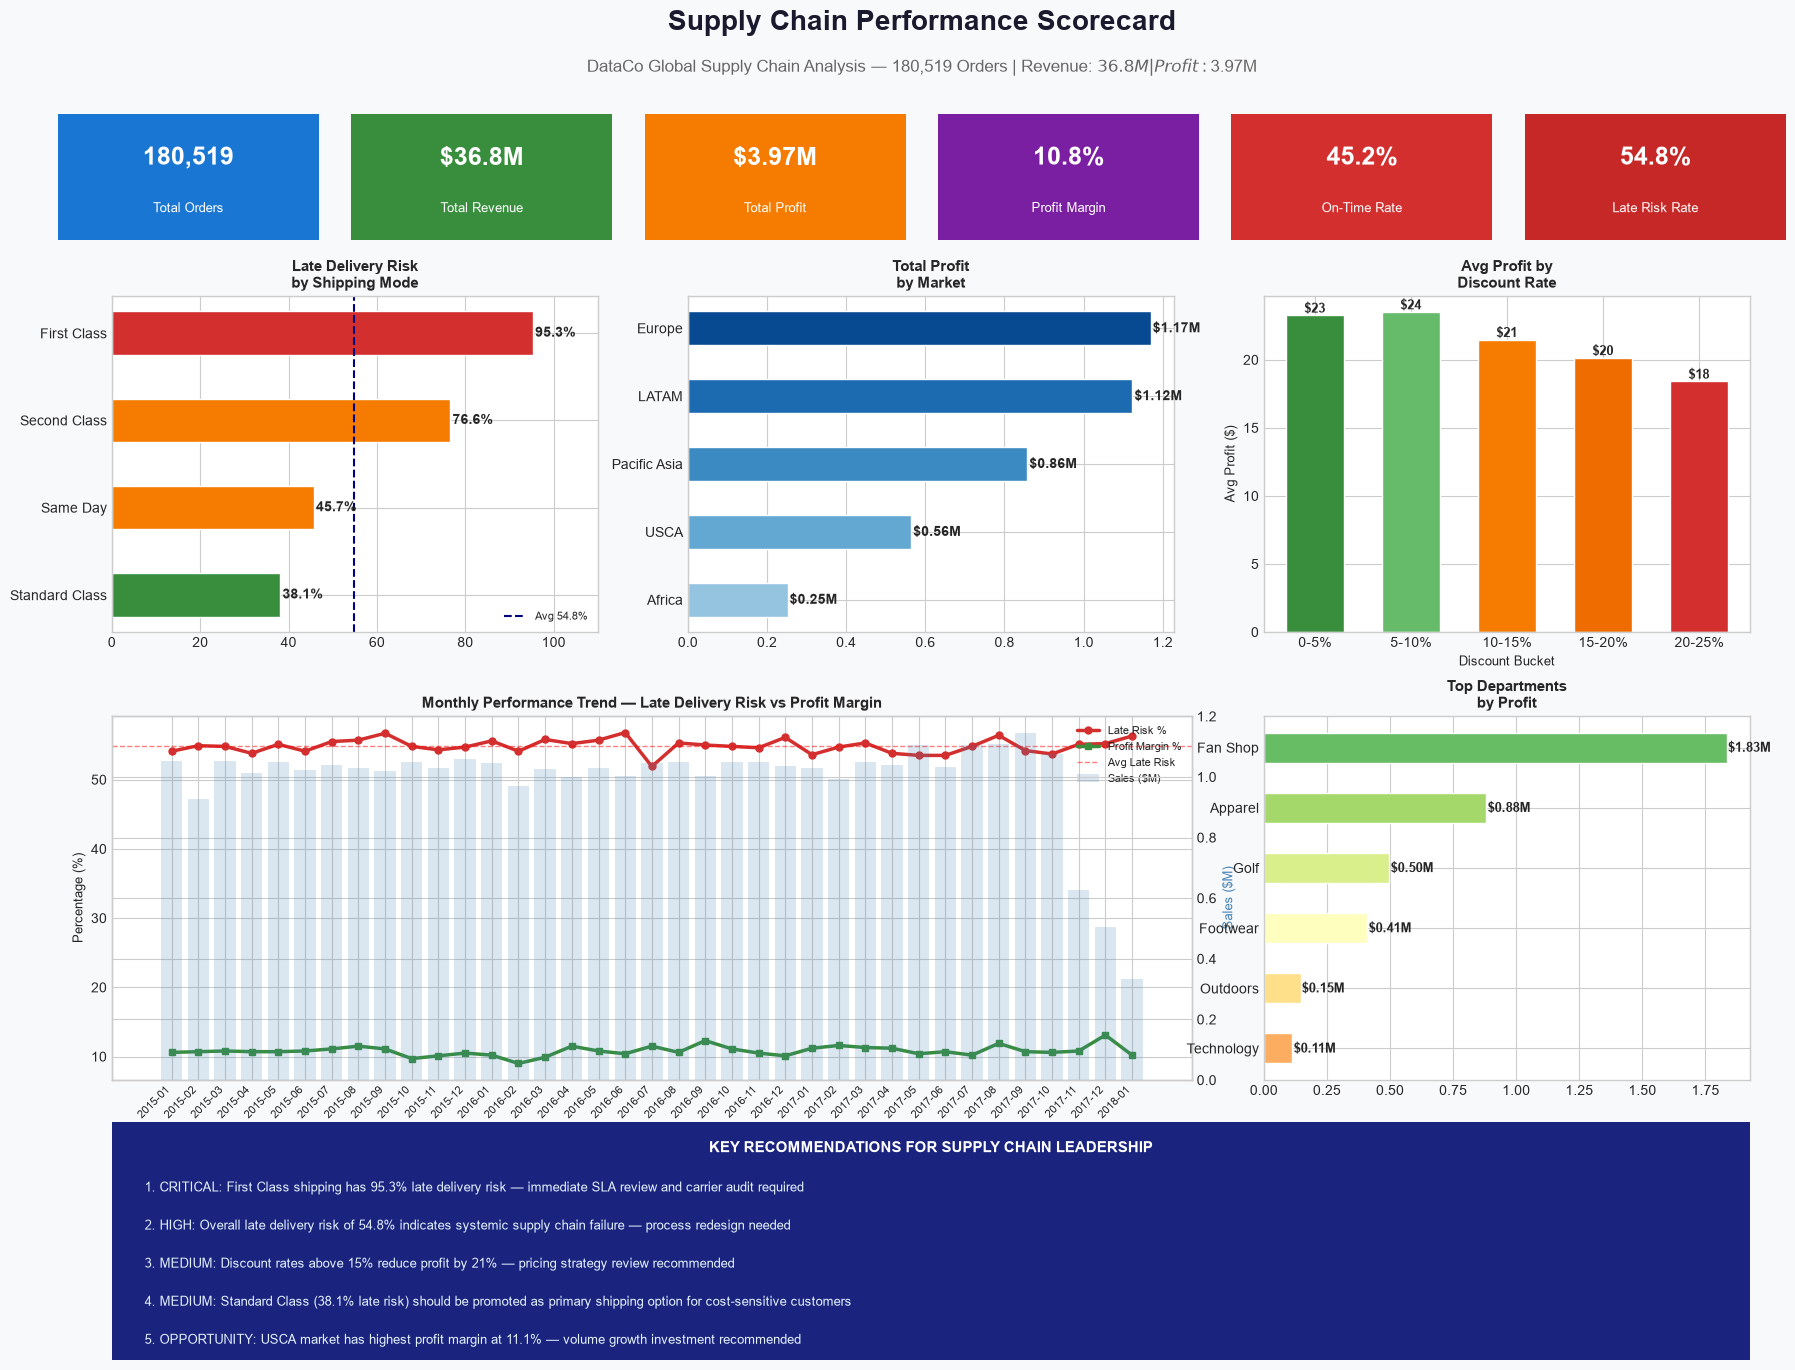

Executive scorecard saved as supply_chain_scorecard.png


In [13]:
# FINAL EXECUTIVE SCORECARD DASHBOARD
fig = plt.figure(figsize=(18, 14))
fig.patch.set_facecolor('#f8f9fa')

# Title
fig.text(0.5, 0.97,
         'Supply Chain Performance Scorecard',
         ha='center', fontsize=20,
         fontweight='bold', color='#1a1a2e')
fig.text(0.5, 0.94,
         'DataCo Global Supply Chain Analysis — 180,519 Orders | '
         'Revenue: $36.8M | Profit: $3.97M',
         ha='center', fontsize=12, color='#666666')

# KPI SCORECARDS ROW
kpi_data = [
    ('Total Orders', '180,519', '#1976d2', '📦'),
    ('Total Revenue', '$36.8M', '#388e3c', '💰'),
    ('Total Profit', '$3.97M', '#f57c00', '📈'),
    ('Profit Margin', '10.8%', '#7b1fa2', '💹'),
    ('On-Time Rate', '45.2%', '#d32f2f', '⚠'),
    ('Late Risk Rate', '54.8%', '#c62828', '🚨'),
]

for i, (label, value, color, icon) in enumerate(kpi_data):
    ax_kpi = fig.add_axes([0.02 + i*0.163, 0.82, 0.145, 0.09])
    ax_kpi.set_facecolor(color)
    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])
    for spine in ax_kpi.spines.values():
        spine.set_visible(False)
    ax_kpi.text(0.5, 0.65, value,
                ha='center', va='center',
                fontsize=18, fontweight='bold',
                color='white',
                transform=ax_kpi.transAxes)
    ax_kpi.text(0.5, 0.25, label,
                ha='center', va='center',
                fontsize=9, color='white',
                transform=ax_kpi.transAxes)

# CHART 1 — Late delivery risk by shipping mode
ax1 = fig.add_axes([0.05, 0.54, 0.27, 0.24])
shipping_plot = shipping_risk.sort_values(
    'late_risk_rate', ascending=True)
colors1 = ['#388e3c', '#f57c00', '#f57c00', '#d32f2f']
bars1 = ax1.barh(shipping_plot['Shipping Mode'],
                 shipping_plot['late_risk_rate'],
                 color=colors1, edgecolor='white',
                 height=0.5)
for bar, rate in zip(bars1, shipping_plot['late_risk_rate']):
    ax1.text(bar.get_width() + 0.5,
             bar.get_y() + bar.get_height()/2,
             f'{rate}%', va='center',
             fontweight='bold', fontsize=10)
ax1.axvline(x=54.8, color='navy',
            linestyle='--', linewidth=1.5,
            label='Avg 54.8%')
ax1.set_xlim(0, 110)
ax1.set_title('Late Delivery Risk\nby Shipping Mode',
              fontweight='bold', fontsize=11)
ax1.legend(fontsize=8)
ax1.set_facecolor('#ffffff')

# CHART 2 — Market profitability
ax2 = fig.add_axes([0.37, 0.54, 0.27, 0.24])
market_plot = market_profit.sort_values(
    'total_profit', ascending=True)
colors2 = plt.cm.Blues(
    np.linspace(0.4, 0.9, len(market_plot)))
bars2 = ax2.barh(market_plot['Market'],
                 market_plot['total_profit'] / 1e6,
                 color=colors2, edgecolor='white',
                 height=0.5)
for bar, val in zip(
    bars2, market_plot['total_profit'] / 1e6):
    ax2.text(bar.get_width() + 0.005,
             bar.get_y() + bar.get_height()/2,
             f'${val:.2f}M',
             va='center', fontweight='bold',
             fontsize=10)
ax2.set_title('Total Profit\nby Market',
              fontweight='bold', fontsize=11)
ax2.set_facecolor('#ffffff')

# CHART 3 — Discount impact
ax3 = fig.add_axes([0.69, 0.54, 0.27, 0.24])
discount_clean = discount_impact.dropna(
    subset=['discount_bucket'])
colors3 = ['#388e3c', '#66bb6a',
           '#f57c00', '#ef6c00', '#d32f2f']
bars3 = ax3.bar(
    discount_clean['discount_bucket'].astype(str),
    discount_clean['avg_profit'],
    color=colors3[:len(discount_clean)],
    edgecolor='white', width=0.6)
for bar, profit in zip(
    bars3, discount_clean['avg_profit']):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.2,
             f'${profit:.0f}',
             ha='center', fontsize=9,
             fontweight='bold')
ax3.set_title('Avg Profit by\nDiscount Rate',
              fontweight='bold', fontsize=11)
ax3.set_xlabel('Discount Bucket', fontsize=9)
ax3.set_ylabel('Avg Profit ($)', fontsize=9)
ax3.set_facecolor('#ffffff')

# CHART 4 — Monthly trend
ax4 = fig.add_axes([0.05, 0.22, 0.60, 0.26])
months_plot = monthly_performance.copy()
x = range(len(months_plot))

ax4_twin = ax4.twinx()
ax4_twin.bar(x, months_plot['total_sales'] / 1e6,
             alpha=0.2, color='steelblue',
             label='Sales ($M)')
ax4_twin.set_ylabel('Sales ($M)', color='steelblue',
                    fontsize=9)

ax4.plot(x, months_plot['late_risk_pct'],
         color='#d32f2f', linewidth=2.5,
         marker='o', markersize=5,
         label='Late Risk %')
ax4.plot(x, months_plot['profit_margin'],
         color='#388e3c', linewidth=2.5,
         marker='s', markersize=5,
         label='Profit Margin %')
ax4.axhline(y=54.8, color='red',
            linestyle='--', linewidth=1,
            alpha=0.5, label='Avg Late Risk')

ax4.set_xticks(x)
ax4.set_xticklabels(months_plot['year_month'],
                    rotation=45, ha='right',
                    fontsize=8)
ax4.set_ylabel('Percentage (%)', fontsize=9)
ax4.set_title('Monthly Performance Trend — Late Delivery Risk vs Profit Margin',
              fontweight='bold', fontsize=11)
lines1, labels1 = ax4.get_legend_handles_labels()
lines2, labels2 = ax4_twin.get_legend_handles_labels()
ax4.legend(lines1 + lines2, labels1 + labels2,
           loc='upper right', fontsize=8)
ax4.set_facecolor('#ffffff')

# CHART 5 — Department performance
ax5 = fig.add_axes([0.69, 0.22, 0.27, 0.26])
dept_plot = dept_performance.sort_values(
    'total_profit', ascending=True).tail(6)
colors5 = plt.cm.RdYlGn(
    np.linspace(0.3, 0.8, len(dept_plot)))
bars5 = ax5.barh(dept_plot['Department Name'],
                 dept_plot['total_profit'] / 1e6,
                 color=colors5, edgecolor='white',
                 height=0.5)
for bar, val in zip(
    bars5, dept_plot['total_profit'] / 1e6):
    ax5.text(bar.get_width() + 0.005,
             bar.get_y() + bar.get_height()/2,
             f'${val:.2f}M',
             va='center', fontweight='bold',
             fontsize=9)
ax5.set_title('Top Departments\nby Profit',
              fontweight='bold', fontsize=11)
ax5.set_facecolor('#ffffff')

# RECOMMENDATIONS BOX
ax_rec = fig.add_axes([0.05, 0.02, 0.91, 0.17])
ax_rec.set_facecolor('#1a237e')
ax_rec.set_xticks([])
ax_rec.set_yticks([])
for spine in ax_rec.spines.values():
    spine.set_visible(False)

recommendations = [
    "1. CRITICAL: First Class shipping has 95.3% late delivery risk — immediate SLA review and carrier audit required",
    "2. HIGH: Overall late delivery risk of 54.8% indicates systemic supply chain failure — process redesign needed",
    "3. MEDIUM: Discount rates above 15% reduce profit by 21% — pricing strategy review recommended",
    "4. MEDIUM: Standard Class (38.1% late risk) should be promoted as primary shipping option for cost-sensitive customers",
    "5. OPPORTUNITY: USCA market has highest profit margin at 11.1% — volume growth investment recommended"
]

ax_rec.text(0.5, 0.92,
            'KEY RECOMMENDATIONS FOR SUPPLY CHAIN LEADERSHIP',
            ha='center', va='top',
            fontsize=11, fontweight='bold',
            color='white',
            transform=ax_rec.transAxes)

for i, rec in enumerate(recommendations):
    ax_rec.text(0.02, 0.75 - i*0.16, rec,
                ha='left', va='top',
                fontsize=9, color='#e3f2fd',
                transform=ax_rec.transAxes)

plt.savefig('supply_chain_scorecard.png',
            dpi=150, bbox_inches='tight',
            facecolor='#f8f9fa')
plt.show()
print("Executive scorecard saved as supply_chain_scorecard.png")

In [14]:
print("""
================================================================
SUPPLY CHAIN PERFORMANCE ANALYSIS — EXECUTIVE SUMMARY
DataCo Global | 180,519 Orders | $36.8M Revenue
================================================================

DATASET
  Source:       DataCo Smart Supply Chain Dataset (Kaggle)
  Records:      180,519 orders
  Revenue:      $36,784,735
  Profit:       $3,966,903
  Profit Margin: 10.8%
  Markets:      5 global markets (Europe, LATAM, 
                Pacific Asia, USCA, Africa)

================================================================
CRITICAL FINDING 1 — LATE DELIVERY CRISIS
================================================================
  Overall Late Delivery Risk:  54.8% of all orders
  On-Time Delivery Rate:       45.2%

  By Shipping Mode:
    First Class:   95.3% late risk (CRITICAL)
    Second Class:  76.6% late risk (HIGH)
    Same Day:      45.7% late risk (MEDIUM)
    Standard Class: 38.1% late risk (BEST PERFORMER)

  Key Insight: Customers paying premium prices for First Class
  shipping experience the WORST delivery performance.
  The operation is systematically failing its highest-value
  customers while Standard Class delivers most reliably.

================================================================
CRITICAL FINDING 2 — SYSTEMIC NOT GEOGRAPHIC
================================================================
  Late delivery risk is almost identical across all markets:
    Europe:       55.2%
    Pacific Asia: 55.0%
    USCA:         54.8%
    Africa:       54.6%
    LATAM:        54.4%

  Key Insight: The problem is not regional. It is a systemic
  operational failure affecting the entire supply chain
  regardless of geography. Root cause is in the shipping
  commitment and fulfillment process itself.

================================================================
FINDING 3 — SHIPPING DAY COMMITMENT FAILURE
================================================================
  Average Scheduled Days: 2.9 days
  Average Actual Days:    3.5 days
  Variance:               +0.57 days overrun

  By Shipping Mode (Scheduled vs Actual):
    First Class:   Promises 1 day — Takes 2.0 days
    Second Class:  Promises 2 days — Takes 4.0 days
    Same Day:      Promises 0 days — Takes 0.5 days
    Standard Class: Promises 4 days — Takes 4.0 days

  Key Insight: Standard Class is the only shipping mode
  that consistently meets its delivery commitment.
  All premium shipping modes are systematically
  overpromising and underdelivering.

================================================================
FINDING 4 — DISCOUNT STRATEGY ERODING PROFITABILITY
================================================================
  Average Discount Rate: 10.2%
  
  Profit by Discount Tier:
    0-5% discount:   $23.26 avg profit per order
    5-10% discount:  $23.51 avg profit per order
    10-15% discount: $21.47 avg profit per order
    15-20% discount: $20.14 avg profit per order
    20-25% discount: $18.41 avg profit per order

  Key Insight: Discounts above 15% reduce average profit
  by 21%. The discounting strategy is not driving
  sufficient volume to offset the margin erosion.

================================================================
FINDING 5 — MARKET AND DEPARTMENT PERFORMANCE
================================================================
  Most Profitable Market:     Europe ($1.17M profit)
  Best Profit Margin Market:  USCA (11.1%)
  Top Department by Profit:   Fan Shop ($1.83M)
  Best Margin Department:     Fitness (11.7%)
  Worst Margin Department:    Book Shop (7.0%)

================================================================
RECOMMENDATIONS IN PRIORITY ORDER
================================================================
  1. CRITICAL — Audit and redesign First Class shipping SLAs
     immediately. 95.3% late risk on premium shipping is
     destroying customer trust and brand reputation.

  2. HIGH — Investigate root cause of systemic 54.8% late
     delivery risk. The identical rate across all markets
     points to a core process or system failure that must
     be identified and fixed at the source.

  3. HIGH — Reposition Standard Class as the flagship
     shipping option. It is the most reliable at 38.1%
     late risk and drives 59.9% of all revenue.

  4. MEDIUM — Cap discount rates at 15% maximum to protect
     profit margins. Discounts above this threshold reduce
     profit by 21% without clear volume benefit.

  5. OPPORTUNITY — Invest in USCA market growth. Highest
     profit margin at 11.1% with significant scale
     potential versus current 14.3% revenue share.

================================================================
TOOLS USED
  Python, Pandas, NumPy, Matplotlib, Seaborn,
  Jupyter Notebook
  
DATASET
  DataCo Smart Supply Chain for Big Data Analysis
  Available at: kaggle.com/datasets/shashwatwork/
  dataco-smart-supply-chain-for-big-data-analysis
================================================================
""")


SUPPLY CHAIN PERFORMANCE ANALYSIS — EXECUTIVE SUMMARY
DataCo Global | 180,519 Orders | $36.8M Revenue

DATASET
  Source:       DataCo Smart Supply Chain Dataset (Kaggle)
  Records:      180,519 orders
  Revenue:      $36,784,735
  Profit:       $3,966,903
  Profit Margin: 10.8%
  Markets:      5 global markets (Europe, LATAM, 
                Pacific Asia, USCA, Africa)

CRITICAL FINDING 1 — LATE DELIVERY CRISIS
  Overall Late Delivery Risk:  54.8% of all orders
  On-Time Delivery Rate:       45.2%

  By Shipping Mode:
    First Class:   95.3% late risk (CRITICAL)
    Second Class:  76.6% late risk (HIGH)
    Same Day:      45.7% late risk (MEDIUM)
    Standard Class: 38.1% late risk (BEST PERFORMER)

  Key Insight: Customers paying premium prices for First Class
  shipping experience the WORST delivery performance.
  The operation is systematically failing its highest-value
  customers while Standard Class delivers most reliably.

CRITICAL FINDING 2 — SYSTEMIC NOT GEOGRAPHIC
  Late d